# 空间转录组概论 & 常见平台的上游定量

In [1]:
import sys
print(sys.executable)

/software/miniconda3/envs/st_env5/bin/python


In [1]:
from datetime import date
print("Author: Biomamba_pudding")
print("Date:", date.today())

Author: Biomamba_pudding
Date: 2025-10-13


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、空间转录组概论

> 空间转录组学是一种能够在组织空间上下文中同时分析基因表达的方法，为理解组织结构、细胞类型分布和细胞互作提供了新的视角。

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/st1.png)

## 1、背景与发展历程
- **传统转录组学**：

  - bulk RNA-seq：平均化了组织内所有细胞的表达信息

  - scRNA-seq：单细胞分辨率，但失去了空间信息
  
  - 组织结构与功能密切相关

  - 需要保留细胞在组织中的空间位置

- **发展历程**：
  1. 早期：基于原位杂交（ISH/FISH）

  2. 高通量空间捕获技术：10x Visium、Slide-seq

  3. 高分辨率方法：MERFISH、seqFISH+
  
  4. 多组学整合：空间转录组 + 单细胞 RNA-seq + xxx

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/st2.png)

## 2、技术分类
| 类别 | 方法 | 特点 | 分辨率 |
|------|------|------|--------|
| 基于条码捕获 | 10x Visium、Slide-seq、SeekSpace、Stereo | 高通量，覆盖整个组织 | ~50-100 μm |
| 基于成像 | MERFISH、seqFISH+ | 单细胞/亚细胞级别，高分辨率 | <1 μm |

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/st3.png)

## 3、实验流程

### 1.3.1 10x Visium

1. **组织制备**：组织切片（一般 5-10 μm），固定于 Visium 空间条码芯片上

2. **染色与成像**：H&E 染色，获取组织图像

3. **RNA 捕获**：组织切片上 mRNA 被芯片上的空间条码捕获

4. **cDNA 合成与测序文库构建**

5. **高通量测序**：生成空间基因表达矩阵

6. **初步分析**：图像对齐、空间坐标匹配

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/10x1.png)

目前10x Visium已经推出HD版本，精度可以达到 2×2 μm大小的spot

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/10x2.png)

可以看出分辨率简直天差地别

### 1.3.2 SeekSpace（高通量条码捕获 + 空间分辨率优化）

1. **组织切片**：固定并贴附于高密度条码芯片

2. **高分辨率 RNA 捕获**：每个 spot 更小（如 8 μm bin）

3. **cDNA 文库构建**：优化 PCR 扩增，保证高灵敏度

4. **测序**：生成高密度空间基因表达矩阵

5. **数据预处理**：
   - 空间坐标映射
   - 图像和表达矩阵结合
   
6. **分析**：
   - 高分辨率细胞类型定位
   - 空间邻域分析

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/ss1.png)

### 1.3.3 Stereo-seq

1. **组织切片**：固定在 DNA nanoball（DNB）芯片上

2. **RNA 捕获**：超高密度 DNB 条码捕获 mRNA

3. **cDNA 合成与测序文库构建**

4. **超高通量测序**：生成亿级 spot 的表达矩阵

5. **数据处理**：
   - 空间坐标精确定位到亚细胞级
   - 可进行单细胞或亚细胞分析

6. **下游分析**：
   - 细胞类型分布
   - 细胞-细胞通讯
   - 组织微结构重建

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/h2.png)

#### Stereo-seq 的 DNA Nanoball (DNB) 技术

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/h3.png)


##### (1) 纳米球是什么？
- **定义**：DNA nanoball（DNB）是一种高度紧密的环状 DNA 分子，通过滚环扩增（Rolling Circle Amplification, RCA）形成直径约 **200–300 nm 的球状 DNA 聚合物**。
- **特点**：
  - 体积小，密度高 → 可以在芯片上排列得非常密集
  - 每个 DNB 含有大量相同的 DNA 拷贝 → 提高信号强度
  - 可附带 **独特条码序列** → 精确标记空间位置

##### (2) 纳米球在 Stereo-seq 中的作用
| 步骤 | 作用 |
|------|------|
| 芯片排列 | DNB 被固定在硅片芯片表面形成超高密度阵列，每个 spot ~200 nm |
| mRNA 捕获 | DNB 上的 polyT 引物捕获组织切片的 mRNA |
| 条码定位 | 每个 DNB 携带唯一空间条码，测序后可以回溯 RNA 的空间位置 |
| 信号放大 | DNB 内含多拷贝 DNA → 测序信号强，减少测序噪声 |

##### (3) 相比传统平台的优势
1. **超高分辨率**：
   - 10x Visium：~50 μm
   - SeekSpace：~8 μm
   - **Stereo-seq**：~200 nm → 接近单细胞甚至亚细胞级别
2. **高通量**：
   - 单个芯片可容纳亿级 DNB spots
   - 可覆盖大面积组织
3. **信号稳定性**：
   - DNB 多拷贝 → 测序噪声低
4. **灵活组合**：
   - 可与 scRNA-seq 或蛋白质组等多组学整合

## 4、空间转录组平台对比

| 平台 | 分辨率 | 通量 | 优势 | 劣势 | 典型应用 |
|------|--------|------|------|------|----------|
| **10x Visium** | ~50 μm/ 2 μm | 中等 | - 简单易用<br>- 商业化成熟<br>- 数据分析工具丰富 | - 不能达到单细胞分辨率<br>- Spot 内可能混合多细胞 | 常规组织结构研究、肿瘤微环境分析 |
| **SeekSpace** | ~8 μm | 高 | - 高分辨率接近单细胞<br>- spot 小，空间信息更精细<br>- 支持邻域分析 | - 商业化程度低<br>- 数据分析较复杂 | 细胞类型精细定位、高分辨率空间邻域分析 |
| **Stereo-seq** | ~200 nm | 超高 | - 亚细胞分辨率<br>- 亿级 spot，高通量<br>- 多拷贝 DNB 信号放大稳定<br>- 可与多组学整合 | - 技术复杂，实验成本高<br>- 数据量巨大，需要高性能计算 | 单细胞/亚细胞研究、复杂组织微结构重建、多组学整合 |


# 三、上游测序数据定量

## 1、10x Visium平台

In [1]:
%%bash
cd /data/04_ST_introduction/data/spaceranger
ls -l

total 3967449
-rw-r--r-- 1 root root 1114656896 Feb  4  2025 Mus_musculus.GRCm39.114.chr.gtf
-rw-r--r-- 1 root root 2773696683 Jan 28  2025 Mus_musculus.GRCm39.dna.toplevel.fa
-rw-r--r-- 1 root root     118332 May 14  2024 Visium_HD_Mouse_Brain_alignment_file.json
drwxrwxr-- 1 1001 1001          0 Mar 27  2024 Visium_HD_Mouse_Brain_fastqs
-rw-r--r-- 1 root root   23065910 May 14  2024 Visium_HD_Mouse_Brain_image.tif
-rw-r--r-- 1 root root    6564767 May 14  2024 Visium_HD_Mouse_Brain_probe_set.csv
-rw-r--r-- 1 root root  144561644 May 14  2024 Visium_HD_Mouse_Brain_tissue_image.tif
drwxr-xr-x 1 1001 1001          0 Jun 18  2020 refdata-gex-mm10-2020-A
drwxrwxr-x 1 1001 1001          0 Jun 12  2025 spaceranger-4.0.1


### 1.1 软件安装

In [ ]:
%%bash

# 下载Space Ranger
wget -O spaceranger-4.0.1.tar.gz "https://cf.10xgenomics.com/releases/spatial-exp/spaceranger-4.0.1.tar.gz?Expires=1755460872&Key-Pair-Id=APKAI7S6A5RYOXBWRPDA&Signature=OcHtPp5rc00BjbHoLZvo1owG9i6222bUJcMCapp9i3RM4qxDfcZaNTlFG-G-cbNUQOJ82yYZL7Tl~mCY1h0yzX~6KiKmOFea-xqL-TGLEPfxFNOlGj~xSi6e1Enf8eAfbugdU7b7FAvg2RCyxHsQzerHGGzUhBxONKvr~XrJOadOmblT1mhe2OYFS-XRf4SAHjjZjWSzqy0N3p~Gw7iqg-cvxMT6E7uK4rHtao6Q07LVf-m--jr8tirsOAdf0MWJp5fHVIdeJ8aENQj5nE-qKuoUf6ngZLutgQp7yfBAmQc7qwAF03gEA1jKzrgI9va4Y1Wc3r3SRA8B2rW7a4mNDw__"
# 这里的链接是有时效性的，请在10x官网注册和申请获取最新的下载链接

tar -xf spaceranger-4.0.1.tar.gz

# 设置环境变量
# 将当前目录（$(pwd)）添加到用户的环境变量 PATH 中，并且把这项设置永久保存在用户的 ~/.bashrc 文件中
echo 'export PATH=/data/04_ST_introduction/spaceranger/spaceranger-4.0.1/:$PATH' >> ~/.bashrc

source  ~/.bashrc
# 检查 Space Ranger是否安装成功
spaceranger

In [4]:
%%bash

# 设置环境变量
# 将当前目录（$(pwd)）添加到用户的环境变量 PATH 中，并且把这项设置永久保存在用户的 ~/.bashrc 文件中
echo 'export PATH=/data/04_ST_introduction/data/spaceranger/spaceranger-4.0.1/:$PATH' >> ~/.bashrc

source  ~/.bashrc
# 检查 Space Ranger是否安装成功
spaceranger

bash: line 8: spaceranger: command not found


CalledProcessError: Command 'b"\n# \xe8\xae\xbe\xe7\xbd\xae\xe7\x8e\xaf\xe5\xa2\x83\xe5\x8f\x98\xe9\x87\x8f\n# \xe5\xb0\x86\xe5\xbd\x93\xe5\x89\x8d\xe7\x9b\xae\xe5\xbd\x95\xef\xbc\x88$(pwd)\xef\xbc\x89\xe6\xb7\xbb\xe5\x8a\xa0\xe5\x88\xb0\xe7\x94\xa8\xe6\x88\xb7\xe7\x9a\x84\xe7\x8e\xaf\xe5\xa2\x83\xe5\x8f\x98\xe9\x87\x8f PATH \xe4\xb8\xad\xef\xbc\x8c\xe5\xb9\xb6\xe4\xb8\x94\xe6\x8a\x8a\xe8\xbf\x99\xe9\xa1\xb9\xe8\xae\xbe\xe7\xbd\xae\xe6\xb0\xb8\xe4\xb9\x85\xe4\xbf\x9d\xe5\xad\x98\xe5\x9c\xa8\xe7\x94\xa8\xe6\x88\xb7\xe7\x9a\x84 ~/.bashrc \xe6\x96\x87\xe4\xbb\xb6\xe4\xb8\xad\necho 'export PATH=/data/04_ST_introduction/data/spaceranger/spaceranger-4.0.1/:$PATH' >> ~/.bashrc\n\nsource  ~/.bashrc\n# \xe6\xa3\x80\xe6\x9f\xa5 Space Ranger\xe6\x98\xaf\xe5\x90\xa6\xe5\xae\x89\xe8\xa3\x85\xe6\x88\x90\xe5\x8a\x9f\nspaceranger\n"' returned non-zero exit status 127.

In [2]:
!spaceranger

spaceranger spaceranger-4.0.1

Process 10x Genomics Visium data

Usage: spaceranger <COMMAND>

Commands:
  count      Count gene expression and protein expression reads from a single
             capture area
  aggr       Aggregate data from multiple 'spaceranger count' runs. Visium HD
             not supported in this release
  segment    Segment nuclei from a microscope image
  mkfastq    Run Illumina demultiplexer on sample sheets that contain
             10x-specific sample index sets
  testrun    Execute the 'count' pipeline on a small test dataset
  mat2csv    Convert a feature-barcode matrix to CSV format
  mkref      Prepare a reference for use with 10x analysis software. Requires a
             GTF and FASTA
  mkgtf      Filter a GTF file by attribute prior to creating a 10x reference
  upload     Upload analysis logs to 10x Genomics support
  sitecheck  Collect Linux system configuration information
  telemetry  Configure and inspect telemetry settings and data
  help      

In [5]:
%%bash

echo


### 1.2 示例数据下载

In [ ]:
%%bash

# 下载10x 官网提供的小鼠示例数据（10X visium HD）
# Input Files
# 空间转录组样本高精度图像文件
wget https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_image.tif
wget https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_tissue_image.tif

# 空间转录组样本高精度图像缩放参数
wget https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_alignment_file.json

# 测序数据
wget https://s3-us-west-2.amazonaws.com/10x.files/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_fastqs.tar


# 小鼠大脑样本的探针集 CSV 文件
wget https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_probe_set.csv

# 下载小鼠参考基因组文件
wget "https://cf.10xgenomics.com/supp/cell-exp/refdata-gex-mm10-2020-A.tar.gz"  #这是10X官网提供的构建好可以直接用于空间转录组分析的基因组文件
tar -xf refdata-gex-mm10-2020-A.tar.gz

#### 参考基因组构建（适用于非模式动物）

In [ ]:
%%bash

# 这里我们自己下载走一遍构建流程
# 下载对应物种的gtf文件
wget https://ftp.ensembl.org/pub/release-114/gtf/mus_musculus/Mus_musculus.GRCm39.114.chr.gtf.gz
gunzip -xf Mus_musculus.GRCm39.114.chr.gtf.gz

# 下载参考基因组的fasta文件
wget https://ftp.ensembl.org/pub/release-114/fasta/mus_musculus/dna/Mus_musculus.GRCm39.dna.toplevel.fa.gz
gunzip -xf Mus_musculus.GRCm39.dna.toplevel.fa.gz

在构建参考基因组前，我们还需要对基因组注释文件进行修饰

`spaceranger mkgtf`：
- 过滤不必要的转录本（如保留最长转录本或主要 isoform）

- 标准化 GTF 字段，确保 gene_id, gene_name, gene_biotype 符合 10x 的解析规则

- 输出一个 经过优化的 GTF 文件，保证 Spaceranger 在生成 Feature-Barcode Matrix 时不会报错或漏掉基因

In [ ]:
%%bash
# 构建参考基因组文件（尤其非模式动物）
cd /data/04_ST_introduction/spaceranger

spaceranger mkgtf Mus_musculus.GRCm39.114.chr.gtf Mus_musculus.GRCm39.114.chr.filtered.gtf \
                   --attribute=gene_biotype:protein_coding \
                   --attribute=gene_biotype:lincRNA \
                   --attribute=gene_biotype:antisense \
                   --attribute=gene_biotype:IG_LV_gene \
                   --attribute=gene_biotype:IG_V_gene \
                   --attribute=gene_biotype:IG_V_pseudogene \
                   --attribute=gene_biotype:IG_D_gene \
                   --attribute=gene_biotype:IG_J_gene \
                   --attribute=gene_biotype:IG_J_pseudogene \
                   --attribute=gene_biotype:IG_C_gene \
                   --attribute=gene_biotype:IG_C_pseudogene \
                   --attribute=gene_biotype:TR_V_gene \
                   --attribute=gene_biotype:TR_V_pseudogene \
                   --attribute=gene_biotype:TR_D_gene \
                   --attribute=gene_biotype:TR_J_gene \
                   --attribute=gene_biotype:TR_J_pseudogene \
                   --attribute=gene_biotype:TR_C_gene

这样就生成了过滤后的gtf注释文件，用于下面构建用于空间转录组的参考基因组文件

In [ ]:
# 生成 mm10 的 spaceranger 参考
spaceranger mkref \
    --genome=mm10 \
    --fasta=Mus_musculus.GRCm39.dna.toplevel.fa \
    --genes=Mus_musculus.GRCm39.114.chr.filtered.gtf 

看一下生成参考基因组的结构

In [ ]:
%%bash

tree -L 3 /data/04_ST_introduction/spaceranger/reference/mm10

/home/chenao/jupyter_home/spaceranger/reference/mm10
├── fasta
│   ├── genome.fa
│   └── genome.fa.fai
├── genes
│   └── genes.gtf.gz
├── reference.json
└── star
    ├── chrLength.txt
    ├── chrNameLength.txt
    ├── chrName.txt
    ├── chrStart.txt
    ├── exonGeTrInfo.tab
    ├── exonInfo.tab
    ├── geneInfo.tab
    ├── Genome
    ├── genomeParameters.txt
    ├── SA
    ├── SAindex
    ├── sjdbInfo.txt
    ├── sjdbList.fromGTF.out.tab
    ├── sjdbList.out.tab
    └── transcriptInfo.tab

3 directories, 19 files


### 1.3 定量

生成这样的文件结构就没有问题了，我们运行最重要的定量步骤 `spaceranger count`

In [7]:
%%bash

# 进行空间转录组数据的定量过程
# 现在可以构建 spaceranger count 命令来从工作目录运行 (spaceranger_tutorial)。如果从不同的目录运行，请相应地修改路径以避免任何错误
cd /data/04_ST_introduction/data/spaceranger

spaceranger count \
    --id=Visium_HD_Mouse_Brain \
    --transcriptome=./refdata-gex-mm10-2020-A/ \
    --fastqs=./Visium_HD_Mouse_Brain_fastqs \
    --probe-set=./Visium_HD_Mouse_Brain_probe_set.csv \
    --cytaimage=./Visium_HD_Mouse_Brain_tissue_image.tif \
    --image=./Visium_HD_Mouse_Brain_image.tif \
    --slide=H1-8CPZTMY \
    --area=A1 \
    --create-bam=false \
    --localcores=20 \
    --localmem=200 &

Thank you for using spaceranger. To help us improve our product,
anonymized telemetry data has been collected and sent to 10X Genomics.
This data helps us understand usage patterns, diagnose issues,
and prioritize improvements.

You can inspect the telemetry metrics sent by looking in
/home/lcpyspa/.cache/tenx/telemetry/spaceranger/spaceranger-4.0.1

For more details on what data is collected and how it's used, please visit
https://10xgen.com/sr-pipeline-telemetry

You can disable telemetry at any time by running the following command:
	spaceranger telemetry disable




ERROR: Reading FASTQ directory
	Caused by: /data/04_ST_introduction/data/spaceranger/Visium_HD_Mouse_Brain_fastqs
	Caused by: Operation not permitted (os error 1)


In [ ]:
%%bash

# 进行空间转录组数据的定量过程
# 现在可以构建 spaceranger count 命令来从工作目录运行 (spaceranger_tutorial)。如果从不同的目录运行，请相应地修改路径以避免任何错误
set -euo pipefail
DATA_DIR=/data/04_ST_introduction/data/spaceranger
OUTPUT_DIR=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain
cd /home/lcpyspa/spa/spa04

sudo /data/04_ST_introduction/data/spaceranger/spaceranger-4.0.1/spaceranger count \
    --id=Visium_HD_Mouse_Brain \
    --output-dir="$OUTPUT_DIR" \
    --transcriptome="$DATA_DIR/refdata-gex-mm10-2020-A" \
    --fastqs=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain_fastqs \
    --probe-set="$DATA_DIR/Visium_HD_Mouse_Brain_probe_set.csv" \
    --cytaimage="$DATA_DIR/Visium_HD_Mouse_Brain_image.tif" \
    --image="$DATA_DIR/Visium_HD_Mouse_Brain_tissue_image.tif" \
    --slide=H1-8CPZTMY \
    --area=A1 \
    --create-bam=false \
    --localcores=20 \
    --localmem=200

sudo: a terminal is required to read the password; either use the -S option to read from standard input or configure an askpass helper


CalledProcessError: Command 'b'\n# \xe8\xbf\x9b\xe8\xa1\x8c\xe7\xa9\xba\xe9\x97\xb4\xe8\xbd\xac\xe5\xbd\x95\xe7\xbb\x84\xe6\x95\xb0\xe6\x8d\xae\xe7\x9a\x84\xe5\xae\x9a\xe9\x87\x8f\xe8\xbf\x87\xe7\xa8\x8b\n# \xe7\x8e\xb0\xe5\x9c\xa8\xe5\x8f\xaf\xe4\xbb\xa5\xe6\x9e\x84\xe5\xbb\xba spaceranger count \xe5\x91\xbd\xe4\xbb\xa4\xe6\x9d\xa5\xe4\xbb\x8e\xe5\xb7\xa5\xe4\xbd\x9c\xe7\x9b\xae\xe5\xbd\x95\xe8\xbf\x90\xe8\xa1\x8c (spaceranger_tutorial)\xe3\x80\x82\xe5\xa6\x82\xe6\x9e\x9c\xe4\xbb\x8e\xe4\xb8\x8d\xe5\x90\x8c\xe7\x9a\x84\xe7\x9b\xae\xe5\xbd\x95\xe8\xbf\x90\xe8\xa1\x8c\xef\xbc\x8c\xe8\xaf\xb7\xe7\x9b\xb8\xe5\xba\x94\xe5\x9c\xb0\xe4\xbf\xae\xe6\x94\xb9\xe8\xb7\xaf\xe5\xbe\x84\xe4\xbb\xa5\xe9\x81\xbf\xe5\x85\x8d\xe4\xbb\xbb\xe4\xbd\x95\xe9\x94\x99\xe8\xaf\xaf\nset -euo pipefail\nDATA_DIR=/data/04_ST_introduction/data/spaceranger\nOUTPUT_DIR=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain\ncd /home/lcpyspa/spa/spa04\n\nsudo spaceranger count \\\n    --id=Visium_HD_Mouse_Brain \\\n    --output

In [ ]:
%%bash

# 进行空间转录组数据的定量过程
# 现在可以构建 spaceranger count 命令来从工作目录运行 (spaceranger_tutorial)。如果从不同的目录运行，请相应地修改路径以避免任何错误
set -euo pipefail
DATA_DIR=/data/04_ST_introduction/data/spaceranger
OUTPUT_DIR=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain_loupe
cd /home/lcpyspa/spa/spa04

sudo /data/04_ST_introduction/data/spaceranger/spaceranger-4.0.1/spaceranger count \
    --id=Visium_HD_Mouse_Brain_loupe \
    --output-dir="$OUTPUT_DIR" \
    --loupe-alignment=/data/04_ST_introduction/data/spaceranger/Visium_HD_Mouse_Brain_alignment_file.json \
    --transcriptome="$DATA_DIR/refdata-gex-mm10-2020-A" \
    --fastqs=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain_fastqs \
    --probe-set="$DATA_DIR/Visium_HD_Mouse_Brain_probe_set.csv" \
    --cytaimage="$DATA_DIR/Visium_HD_Mouse_Brain_image.tif" \
    --image="$DATA_DIR/Visium_HD_Mouse_Brain_tissue_image.tif" \
    --slide=H1-8CPZTMY \
    --area=A1 \
    --create-bam=false \
    --localcores=20 \
    --localmem=200

sudo: a terminal is required to read the password; either use the -S option to read from standard input or configure an askpass helper


CalledProcessError: Command 'b'\n# \xe8\xbf\x9b\xe8\xa1\x8c\xe7\xa9\xba\xe9\x97\xb4\xe8\xbd\xac\xe5\xbd\x95\xe7\xbb\x84\xe6\x95\xb0\xe6\x8d\xae\xe7\x9a\x84\xe5\xae\x9a\xe9\x87\x8f\xe8\xbf\x87\xe7\xa8\x8b\n# \xe7\x8e\xb0\xe5\x9c\xa8\xe5\x8f\xaf\xe4\xbb\xa5\xe6\x9e\x84\xe5\xbb\xba spaceranger count \xe5\x91\xbd\xe4\xbb\xa4\xe6\x9d\xa5\xe4\xbb\x8e\xe5\xb7\xa5\xe4\xbd\x9c\xe7\x9b\xae\xe5\xbd\x95\xe8\xbf\x90\xe8\xa1\x8c (spaceranger_tutorial)\xe3\x80\x82\xe5\xa6\x82\xe6\x9e\x9c\xe4\xbb\x8e\xe4\xb8\x8d\xe5\x90\x8c\xe7\x9a\x84\xe7\x9b\xae\xe5\xbd\x95\xe8\xbf\x90\xe8\xa1\x8c\xef\xbc\x8c\xe8\xaf\xb7\xe7\x9b\xb8\xe5\xba\x94\xe5\x9c\xb0\xe4\xbf\xae\xe6\x94\xb9\xe8\xb7\xaf\xe5\xbe\x84\xe4\xbb\xa5\xe9\x81\xbf\xe5\x85\x8d\xe4\xbb\xbb\xe4\xbd\x95\xe9\x94\x99\xe8\xaf\xaf\nset -euo pipefail\nDATA_DIR=/data/04_ST_introduction/data/spaceranger\nOUTPUT_DIR=/home/lcpyspa/spa/spa04/Visium_HD_Mouse_Brain_loupe\ncd /home/lcpyspa/spa/spa04\n\nsudo /data/04_ST_introduction/data/spaceranger/spaceranger-4.0.1/spa

| 参数                                                                                         | 作用                                                                |
| ------------------------------------------------------------------------------------------ | ----------------------------------------------------------------- |
| `spaceranger count`                                                                        | Space Ranger 的核心命令，用于对 Visium 空间转录组数据进行建索引、对齐和生成空间基因表达矩阵。         |
| `--id=Visium_HD_Mouse_Brain`                                                               | 本次分析的输出文件夹名称，也作为 sample 名称。最终结果会生成在 `outs` 目录下。                   |
| `--transcriptome=./refdata-gex-mm10-2020-A/` | 指定参考基因组/转录组路径（这里是小鼠 mm10 参考），Space Ranger 会用它进行 RNA-seq reads 对齐。 |
| `--fastqs=./Visium_HD_Mouse_Brain_fastqs`                                                  | FASTQ 文件的路径，也就是测序输出的原始数据。                                         |
| `--probe-set=./Visium_HD_Mouse_Brain_probe_set.csv`                                        | 指定 Visium HD 探针集 CSV 文件，用于对高密度探针捕获的 mRNA 进行定位和计数。                 |
| `--cytaimage=./Visium_HD_Mouse_Brain_tissue_image.tif`                                     | 高分辨率组织图像（如 H\&E 图像），用于组织轮廓和空间坐标对齐。                                |
| `--image=./Visium_HD_Mouse_Brain_image.tif`                                                | 低分辨率组织图像或组织贴片缩略图，用于辅助图像对齐。                                        |
| `--slide=H1-8CPZTMY`                                                                       | 指定 Visium 芯片编号，对应实验实际使用的芯片。                                       |
| `--area=A1`                                                                                | 芯片上组织覆盖的区域编号，对应 10x Visium HD 的具体 capture area。                   |
| `--create-bam=false`                                                                       | 是否生成 BAM 文件。如果设置为 `false`，不会生成 BAM，可以节省存储空间。                      |
| `--localcores=30`                                                                          | 指定本地 CPU 核心数，用于加速计算。                                              |
| `--localmem=300`                                                                           | 指定本地内存（GB），用于分配给 Space Ranger 运行。                                 |
| `&`                                                                                        | 在 Linux shell 中表示后台运行命令，不阻塞终端。                                    |

### 1.4 结果文件概况

生成结果文件结构如下：

In [ ]:
%%bash
# 查看输出结果文件夹
tree -L 2 /data/04_ST_introduction/spaceranger/Visium_HD_Mouse_Brain/

/home/chenao/jupyter_home/downstream/output_files
├── binned_outputs
│   ├── square_002um
│   ├── square_008um
│   └── square_016um
├── spatial
│   ├── aligned_fiducials.jpg
│   ├── aligned_tissue_image.jpg
│   ├── cytassist_image.tiff
│   ├── detected_tissue_image.jpg
│   ├── tissue_hires_image.png
│   └── tissue_lowres_image.png
├── Visium_HD_Mouse_Brain_binned_outputs.tar.gz
├── Visium_HD_Mouse_Brain_cloupe_008um.cloupe
├── Visium_HD_Mouse_Brain_feature_slice.h5
├── Visium_HD_Mouse_Brain_metrics_summary.csv
├── Visium_HD_Mouse_Brain_molecule_info.h5
├── Visium_HD_Mouse_Brain_spatial.tar.gz
└── Visium_HD_Mouse_Brain_web_summary.html

5 directories, 13 files


可以从summary文件中获取基本结果信息，用于评判数据基本质量

基本概况：

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/10x3.png)

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/10x4.png)

当然也提供了csv直接读取相应数据

In [8]:
%%bash

head /data/04_ST_introduction/spaceranger/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_metrics_summary.csv

head: cannot open '/data/04_ST_introduction/spaceranger/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_metrics_summary.csv' for reading: No such file or directory


CalledProcessError: Command 'b'\nhead /data/04_ST_introduction/spaceranger/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_metrics_summary.csv\n'' returned non-zero exit status 1.

#### Space Ranger Metrics 说明

| 列名 | 含义 |
|------|------|
| Sample ID | 样本名称或分析 ID |
| Number of Reads | 总测序读数 (reads) 数量 |
| Valid Barcodes | 被识别为有效空间条码的数量 |
| Valid UMIs | 被识别为有效 UMI 的数量 |
| Sequencing Saturation | 测序饱和度（UMI 重复率），反映测序是否足够深 |
| Q30 Bases in Barcode | 条码序列中 Q30（高质量）碱基比例 |
| Q30 Bases in Probe Read | 探针读长中 Q30 碱基比例 |
| Q30 Bases in UMI | UMI 序列中 Q30 碱基比例 |
| Reads Mapped to Probe Set | 对探针集成功比对的读数 |
| Reads Mapped Confidently to Probe Set | 高置信度比对到探针集的读数 |
| Fraction Reads in Squares Under Tissue | 组织覆盖区域内的 reads 比例 |
| Genes Detected | 检测到的基因数量 |
| Reads Mapped Confidently to the Filtered Probe Set | 高置信度比对到过滤后探针集的 reads 数 |
| Number of Genes | 检测到的基因数（与 Genes Detected 类似） |
| Reads Half-Mapped to Probe Set | 部分比对到探针集的 reads |
| Reads Split-Mapped to Probe Set | 被拆分比对到探针集的 reads |
| Estimated UMIs from Genomic DNA | 推测来自基因组 DNA 的 UMI 数 |
| Estimated UMIs from Genomic DNA per Unspliced Probe | 每个未剪接探针对应的基因组 DNA UMI 数 |
| Number of Squares Under Tissue 2/8/16 µm | 2/8/16 µm 网格下组织覆盖的格子数量 |
| Mean Reads Under Tissue per Square 2/8/16 µm | 每个 2/8/16 µm 网格的平均 reads 数 |
| Fraction of Squares Under Tissue 2/8/16 µm | 2 µm 网格中覆盖组织的比例 |
| Mean Genes Under Tissue per Square 2/8/16 µm | 每个 2/8/16 µm 网格平均检测到的基因数 |
| Mean UMIs Under Tissue per Square 2/8/16 µm | 每个 2/8/16 µm 网格平均 UMI 数 |
| Total Genes Detected Under Tissue 2/8/16 µm | 2/8/16 µm 网格组织区域检测到的总基因数 |

## 2、SeekSpace 平台

### 2.1 软件安装

In [ ]:
%%bash

# 下载seekspace需要分析软件seekspacetools

mkdir seekspacetools_v1.0.0
cd seekspacetools_v1.0.0
wget -c -O seekspacetools_v1.0.0.tar.gz "https://seekgene-public.oss-cn-beijing.aliyuncs.com/software/seekspacetools/seekspacetools_v1.0.0.tar.gz"

# 解压
tar -xf seekspacetools_v1.0.0.tar.gz

# 安装
source ./bin/activate
./bin/conda-unpack

# 将软件路径添加到全局变量中
export PATH=/data/04_ST_introduction/data/seekspace/seekspacetools_v1.0.0/bin:$PATH
source  ~/.bashrc

### 2.2 下载示例数据

这里我们下载官网提供的小鼠大脑demo数据

In [ ]:
%%bash

# 存放demo数据
mkdir -p /data/04_ST_introduction/seekspace/data
cd /data/04_ST_introduction/seekspace/data

# 下载测试数据
wget -c -O demo.tar "https://seekgene-public.oss-cn-beijing.aliyuncs.com/software/data/demodata/space/demo.tar"
# decompress
tar -xf demo.tar

# 下载参考基因组文件
wget -c -O mm10.tar.gz "https://seekgene-public.oss-cn-beijing.aliyuncs.com/software/data/reference/mm10.tar.gz"

# 解压缩
tar -zxvf mm10.tar.gz

### 2.3 参考基因组构建（兼容10X genomics格式）

In [ ]:
# 这里我们同样走一遍参考基因组文件的构建流程
# seekspacetool支持兼容10X的cellranger构建的参考基因组

# cellranger mkgtf Homo_sapiens.GRCh38.ensembl.gtf Homo_sapiens.GRCh38.ensembl.filtered.gtf \
#    --attribute=gene_biotype:protein_coding \
#    --attribute=gene_biotype:lncRNA \
#    --attribute=gene_biotype:antisense \
#    --attribute=gene_biotype:IG_LV_gene \
#    --attribute=gene_biotype:IG_V_gene \
#    --attribute=gene_biotype:IG_V_pseudogene \
#    --attribute=gene_biotype:IG_D_gene \
#    --attribute=gene_biotype:IG_J_gene \
#    --attribute=gene_biotype:IG_J_pseudogene \
#    --attribute=gene_biotype:IG_C_gene \
#    --attribute=gene_biotype:IG_C_pseudogene \
#    --attribute=gene_biotype:TR_V_gene \
#    --attribute=gene_biotype:TR_V_pseudogene \
#    --attribute=gene_biotype:TR_D_gene \
#    --attribute=gene_biotype:TR_J_gene \
#    --attribute=gene_biotype:TR_J_pseudogene \
#    --attribute=gene_biotype:TR_C_gene

#cellranger mkref --genome=GRCh38 --fasta=GRCh38.fa --genes=GRCh38-filtered-ensembl.gtf
#cd GRCh38/genes
#gunzip -dc genes.gtf.gz > genes.gtf

In [ ]:
%%bash

# 如果只使用 seekspace构建 则运行：
/demo/seekspacetools_v1.0.0/bin/STAR \
  --runMode genomeGenerate \
  --runThreadN 16 \
  --genomeDir /path/to/star \
  --genomeFastaFiles /path/to/genome.fa \
  --sjdbGTFfile /path/to/genome.gtf \
  --sjdbOverhang 149 \
  --limitGenomeGenerateRAM 17179869184

参数说明：

| 参数 | 示例值 | 含义 |
|------|--------|------|
| `--runMode` | `genomeGenerate` | 指定 STAR 的运行模式，这里选择 **构建参考基因组索引**（而不是比对 reads） |
| `--runThreadN` | `16` | 使用的线程数，推荐设置为服务器可用 CPU 数的一半或更多，以加快索引构建速度 |
| `--genomeDir` | `/path/to/star` | 输出目录路径，用于存放生成的 STAR 基因组索引文件 |
| `--genomeFastaFiles` | `/path/to/genome.fa` | 输入的参考基因组 FASTA 文件路径，通常是 `.fa` 或 `.fasta` 格式 |
| `--sjdbGTFfile` | `/path/to/genome.gtf` | 基因组注释文件 GTF，用于提供外显子-内含子边界信息（对后续转录组比对和 splice-aware mapping 很关键） |
| `--sjdbOverhang` | `149` | 设置剪接位点数据库（splice junction DB）的 overhang 长度。通常设为 **read length - 1**（例如 reads 长度为 150bp，则设置 149） |
| `--limitGenomeGenerateRAM` | `17179869184` | STAR 构建基因组索引时的最大内存（RAM）限制，单位为字节（这里是 16 GB，即 17179869184 ≈ 16×1024³）。需要根据基因组大小调整 |

### 2.4 定量

示例1：基本用法

为分析设置必要的配置文件，包括样本数据的路径、试剂类型、基因组索引、GTF等。使用以下命令运行SeekSpace® Tools：

In [ ]:
%%bash

seekspacetools run \
    --fq1 /data/04_ST_introduction/data/seekspace/demo/demo_expression_S8_L007_R1_001.fastq.gz \
    --fq2 /data/04_ST_introduction/data/seekspace/demo/demo_expression_S8_L007_R2_001.fastq.gz \
    --spatialfq1 /data/04_ST_introduction/data/seekspace/demo/demo_spatial_S7_L007_R1_001.fastq.gz \
    --spatialfq2 /data/04_ST_introduction/data/seekspace/demo/demo_spatial_S7_L007_R2_001.fastq.gz \
    --hdmifq /data/04_ST_introduction/data/seekspace/demo/2P231224030A4.fq.gz \
    --samplename demo \
    --outdir /data/04_ST_introduction/data/seekspace/demo/outdir \
    --genomeDir /home/data/04_ST_introduction/data/seekspace/mm10/star \
    --gtf /home/data/04_ST_introduction/data/seekspace/mm10/genes/genes.gtf \
    --chemistry DDVS \
    --core 10 \
    --include-introns \
    --forceCell 80000 \
    --min_umi 200 \
    --chip_id 2P231224030A4 \
    --DAPI /data/04_ST_introduction/data/seekspace/demo/2P231224030A4.tif &

参数说明：

| 参数 | 示例值 | 含义 |
|------|--------|------|
| `--fq1` | `/home/.../demo_expression_S8_L007_R1_001.fastq.gz` | 表达测序数据的 Read1 FASTQ 文件（含 cell barcode + UMI 序列） |
| `--fq2` | `/home/.../demo_expression_S8_L007_R2_001.fastq.gz` | 表达测序数据的 Read2 FASTQ 文件（含转录本序列）|
| `--spatialfq1` | `/home/.../demo_spatial_S7_L007_R1_001.fastq.gz` | 空间测序数据的 Read1 FASTQ 文件 |
| `--spatialfq2` | `/home/.../demo_spatial_S7_L007_R2_001.fastq.gz` | 空间测序数据的 Read2 FASTQ 文件 |
| `--hdmifq` | `/home/.../2P231224030A4.fq.gz` | 高密度 (HDMI) 探针测序 FASTQ 文件，用于空间条码解码 |
| `--samplename` | `demo` | 样本名称，输出文件和目录会用到 |
| `--outdir` | `/home/.../outdir` | 输出目录，所有结果文件会写到这里 |
| `--genomeDir` | `/home/.../mm10/star` | 参考基因组索引目录（由 STAR 生成） |
| `--gtf` | `/home/.../mm10/genes/genes.gtf` | 参考基因组的注释文件 (GTF)，用于基因模型和转录本注释 |
| `--chemistry` | `DDVS` | 测序化学类型，Seekspace 特定（如 DDVS） |
| `--core` | `10` | 使用的 CPU 核心数 |
| `--include-introns` | *无值开关* | 是否包含 **内含子 reads**（在一些情况下有助于捕获未剪接 RNA 或核 RNA） |
| `--forceCell` | `80000` | 强制指定最大细胞数（或条码数），跳过自动估计 |
| `--min_umi` | `200` | 过滤阈值：细胞至少需要有 200 UMI 才保留 |
| `--chip_id` | `2P231224030A4` | 芯片 ID，用于与图像、HDMI 探针文件匹配 |
| `--DAPI` | `/home/.../2P231224030A4.tif` | DAPI 染色图像文件，用于与空间条码定位对齐 |

In [ ]:
=== Seekspace run started at Tue 19 Aug 2025 08:49:38 AM UTC ===
2025-08-19 08:49:47.275 | INFO     | seekspacetools.utils.preflight:preflight_check:8 - start preflight check!
2025-08-19 08:49:47.276 | INFO     | seekspacetools.utils.preflight:preflight_check:13 - check RNA library
2025-08-19 08:49:47.276 | INFO     | seekspacetools.utils.wrappers:cmd_execute:39 - zcat "./jupyter_home/seekspace/data/demo/demo_expression_S8_L007_R1_001.fastq.gz"|head -n 400000|gzip > ./jupyter_home/seekspace/data/outdir/Analysis/.PREFLIGHT_CHECK/.test/data/demo_expression_S8_L007_R1_001.fastq.gz
2025-08-19 08:49:49.456 | INFO     | seekspacetools.utils.wrappers:cmd_execute:39 - zcat "./jupyter_home/seekspace/data/demo/demo_expression_S8_L007_R2_001.fastq.gz"|head -n 400000|gzip > ./jupyter_home/seekspace/data/outdir/Analysis/.PREFLIGHT_CHECK/.test/data/demo_expression_S8_L007_R2_001.fastq.gz
2025-08-19 08:49:51.073 | INFO     | seekspacetools.utils.barcode:chemistry_auto:133 - test DDVS!
2025-08-19 08:49:51.074 | INFO     | seekspacetools.utils.barcode:barcode_main:406 - extract barcode start!
2025-08-19 08:49:51.859 | INFO     | seekspacetools.utils.barcode:barcode_main:417 - barcode one base mismatch allowed.
2025-08-19 08:49:51.859 | INFO     | seekspacetools.utils.barcode:barcode_main:428 - rescue barcode match multi barcode in whitelist.
2025-08-19 08:50:05.002 | INFO     | seekspacetools.utils.barcode:barcode_main:472 - deal multi start!
2025-08-19 08:50:05.063 | INFO     | seekspacetools.utils.barcode:barcode_main:524 - deal multi done!
2025-08-19 08:50:05.068 | INFO     | seekspacetools.utils.barcode:barcode_main:528 - extract barcode done!
2025-08-19 08:50:05.200 | INFO     | seekspacetools.utils.barcode:chemistry_auto:138 - valid barcode rate of DDVS: 93.045%
2025-08-19 08:50:05.200 | INFO     | seekspacetools.utils.wrappers:cmd_execute:36 - STAR --runThreadN 1 --limitOutSJcollapsed 5000000 --readMapNumber -1 --genomeDir ./jupyter_home/seekspace/data/mm10/star --readFilesCommand zcat --outFileNamePrefix ./jupyter_home/seekspace/data/outdir/Analysis/.PREFLIGHT_CHECK/.test/test_1M_ --outSAMtype BAM Unsorted --readFilesIn ./jupyter_home/seekspace/data/outdir/Analysis/.PREFLIGHT_CHECK/.test/DDVS/step1/DDVS_2.fq.gz
2025-08-19 08:50:21.509 | INFO     | seekspacetools.utils.barcode:mapping_report:45 - 

生成这样的输出文件就说明我们已经运行成功了(这里如果java高于openjdk10可能会导致qc过程报错，如果需要请保证java环境低于该版本)

---

### 2.5 结果文件概况

In [ ]:
检查一下生成的目录

In [ ]:
!tree -L 3  /data/04_ST_introduction/data/seekspace/demo/outdir

/home/chenao/jupyter_home/seekspace/data/outdir
├── Analysis
│   ├── scRNA-seq_Analysis
│   │   ├── demo_summary.csv
│   │   ├── demo_summary.json
│   │   ├── step1
│   │   ├── step2
│   │   └── step3
│   ├── Spatial_Positioning
│   │   ├── demo_cell_locations.csv
│   │   ├── demo_spatial_barcode_counts.csv.gz
│   │   ├── demo_spatial_summary.csv
│   │   ├── demo_spatial_umis_cleaned.csv.gz
│   │   ├── demo_spatial_umis.csv.gz
│   │   └── demo_valid_spatial_umis.csv.gz
│   └── Tissue_Detection
│       ├── demo_aligned_DAPI.png
│       ├── demo_bc_under_tissue.csv
│       └── demo_processed_DAPI.png
└── Outs
    ├── clustering
    │   ├── demo.rds
    │   ├── FeatureScatter.png
    │   ├── FindAllMarkers.xls
    │   ├── mito_quantile.xls
    │   ├── nCount_quantile.xls
    │   ├── nFeature_quantile.xls
    │   ├── resolution.xls
    │   ├── top10_heatmap.png
    │   ├── tsne.png
    │   ├── tsne_umi.png
    │   ├── tsne_umi.xls
    │   ├── umap.png
    │   └── VlnPlot.png
    ├── demo_a

seekspace定量结果如上

也提供了html和csv文件供我们查询定量结果质量

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/seekspace1.png)

总体共检测到26，464个cell，细胞检测基因中位数为548，平均UMI为759

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/seekspace2.png)

Summary Table 指标解释

| 指标 | 含义 | 参考区间 / 解读 |
|------|------|----------------|
| **Estimated Number of Cells (RNA)** | 根据转录组数据估算的细胞总数 | 与捕获效率相关，越多越好 |
| **Number of Cells with Unique Center** | 有唯一中心点的细胞数 | 表示去重和定位后的有效细胞数 |
| **Number of Cells Under Tissue Coverage** | 实际位于组织区域的细胞数 | 略少于总捕获数 |
| **Median Genes per Cell** | 每个细胞检测到的基因数（中位数） | 常见 200–3,000，越高说明表达信息更丰富 |
| **Median UMI per Cell** | 每个细胞的 UMI 中位数 | 常见 500–10,000，越高说明捕获效率更好 |
| **Mean Reads per Cell** | 每个细胞的平均测序 reads 数 | 与文库测序深度相关 |
| **Fraction Reads in Cells** | 映射到细胞的 reads 占比 | 常见 50%–80%，越高说明背景噪音低 |
| **Total Genes Detected** | 数据中检测到的基因总数 | 一般 15,000–25,000，基因数越多越全面 |

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/seekspace3.png)

Spatial Library 指标解释

| 指标 | 含义 | 参考区间 / 解读 |
|------|------|----------------|
| **Total Spatial Reads** | 空间转录组实验获得的测序总 reads 数 | 越多说明测序更充分 |
| **Valid Spatial Reads** | 通过质控的有效 reads 数 | 一般 >80% |
| **Total Spatial UMIs** | 从 reads 中识别到的唯一 UMI 总数 | 反映转录本捕获数量 |
| **Spatial Barcode Saturation** | 条形码饱和度（测序冗余度） | 常见 50%–80%，过高说明冗余 |
| **Valid Spatial UMIs** | 质控后可用的空间 UMI 数 | 应接近 Total Spatial UMIs |
| **Spatial UMIs with Unique Locations** | 能唯一定位到空间坐标的 UMI 百分比 | >90% 较理想 |
| **Accurate Spatial UMIs** | 高置信度定位到 spot 的 UMI 百分比 | 常见 10%–30%，越高越可靠 |
| **Accurate Spatial UMI Bins** | 包含准确 UMI 的空间 bin 比例 | 应接近 100% |
| **Cell-Identified Spatial UMIs** | 能分配给细胞的空间 UMI 百分比 | 常见 30%–50% |
| **Mean Spatial UMIs per Cell** | 每个细胞平均空间 UMI 数 | 常见 50–500，越高说明捕获效率更好 |

同样这些数据也可以通过 /Outs/demo_summary.csv 获取

In [ ]:
%%bash

head -n 5 /data/04_ST_introduction/seekspace/outdir/Outs/demo_summary.csv | cut -d',' -f1-5

Samplename,Estimated_Number_of_Cells_rna,Number_of_Cells_with_Unique_Center,Number_of_Cells_Under_Tissue_Coverage,Median_Genes_per_Cell
demo,35770,28149,26464,548


-----

### 2.6 读取为Anndata对象

In [1]:
# 加载基础库
import scanpy as sc
import pandas as pd
import os
import matplotlib.pyplot as plt
plt.rcdefaults()

In [ ]:
data_dir = "/data/04_ST_introduction/seekspace/outdir/Outs/demo_filtered_feature_bc_matrix/"  # 修改为你的路径

# 可以直接使用scanpy的read_10x_mtx读取表达矩阵
adata = sc.read_10x_mtx(
    data_dir,               
    var_names='gene_symbols',  
    cache=True
)

print(adata)

AnnData object with n_obs × n_vars = 26464 × 28158
    var: 'gene_ids', 'feature_types'


In [4]:
adata.obs

""
ACAGGGAATGAAACCCAAGCGACGGAT
ACCATTTATGCAGCAGTTAGTCATACG
ACCATTTTACGAAGTGACCTAATAACG
AGATAGAGCTACGACTTCCTAATAACG
AGCTTCCCGATCGAAGGGCTCTGCTTC
...
ACACCAAGCTAGCAATAGGACTGTGGA
GACCAATGCTCGGATCCAGCGACGGAT
TATCGCCATGCGCATAAAGCGACGGAT
TGCTTGCGCTGGCAGATCCTAATAACG


In [5]:
adata.var

,gene_ids,feature_types
Xkr4,ENSMUSG00000051951,Gene Expression
Gm37381,ENSMUSG00000102343,Gene Expression
Rp1,ENSMUSG00000025900,Gene Expression
Sox17,ENSMUSG00000025902,Gene Expression
Gm37323,ENSMUSG00000104328,Gene Expression
...,...,...
AC168977.1,ENSMUSG00000079808,Gene Expression
AC149090.1,ENSMUSG00000095041,Gene Expression
CAAA01118383.1,ENSMUSG00000063897,Gene Expression
Vmn2r122,ENSMUSG00000096730,Gene Expression


In [6]:
# 读取空间坐标(存在cell_locations.tsv.gz中)
loc = pd.read_csv(os.path.join(data_dir, "cell_locations.tsv.gz"),
                  sep='\t', index_col=0)

print(loc.head())
print(loc.columns)

                                 X      Y
Cell_Barcode                             
AAACCCAATGAAACCATAAGGCACTAT  21787  16874
AAACCCAATGAAACCATGGACTGTGGA  32707  10284
AAACCCAATGCCGAGTGAAGGCACTAT  22737   9885
AAACCCAATGCCGAGTGGCTCTGCTTC  37394   7228
AAACCCAATGCCGAGTGTAGTCATACG  20748  11338
Index(['X', 'Y'], dtype='object')


In [7]:
# 对齐 obs
loc = loc.loc[adata.obs_names, ['X','Y']]

In [8]:
# 添加到 AnnData
adata.obs = adata.obs.join(loc)

In [ ]:
# 添加到 obsm 坐标中
adata.obsm['X_spatial'] = loc.values

In [9]:
adata

AnnData object with n_obs × n_vars = 26464 × 28158
    obs: 'X', 'Y'
    var: 'gene_ids', 'feature_types'

可以用于后续空间转录组分析

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/ss2.png)

---

## 3、Stereo-seq 平台

### 3.1 软件下载与安装

In [ ]:
%%bash

##wtih curl
curl -o saw-8.1.3.tar.gz "https://cdn-newfile.stomics.tech/saw-8.1.3.tar.gz"

##or with wget
wget -O saw-8.1.3.tar.gz "https://cdn-newfile.stomics.tech/saw-8.1.3.tar.gz"

##参考基因组下载
wget -c ftp://ftp2.cngb.org/pub/stomics/STT0000124/supp/reference-data-mouse.tar.gz

In [ ]:
## 解压
cd /saw/package
tar -xzf saw-8.1.3.tar.gz

### 3.2 构建参考基因组（非模式动物）

In [ ]:
%%bash

cd /data/04_ST_introduction/saw/datasets/reference

saw makeRef \
    --mode=STAR \
    --fasta=/path/to/FASTA1 \
    --gtf=/path/to/GTF/or/GFF \
    --genome=./transcriptome

SAW makeRef 参数说明

| 参数 | 示例值 | 含义 |
|------|--------|------|
| `--mode` | `STAR` | 选择构建索引的方式，通常使用 `STAR` 作为比对器 |
| `--fasta` | `/path/to/FASTA` | 参考基因组序列文件（FASTA 格式） |
| `--gtf` | `/path/to/GTF/or/GFF` | 基因注释文件（GTF 或 GFF 格式），包含基因坐标和功能注释 |
| `--genome` | `./transcriptome` | 指定输出索引的目录或名称，用于后续比对 |

In [ ]:
%%bash

# 如果不关注细胞中的rRNA信息，也可以选择去除rRNA   --rRNA-FASTA 参数来指定 rRNA 信息，将添加其到参考基因组 --fasta 中

saw makeRef \
    --mode=STAR \
    --fasta=/path/to/FASTA \
    --gtf=/path/to/GTF/or/GFF \
    --rRNA-fasta=/path/to/rRNA/FASTA \
    --genome=./transcriptome_with_rRNA

### 3.3 定量

`SAW count` 是分析软件包的核心部分，支持处理绝大部分的 Stereo-seq FF，Stereo-seq FFPE 和 Stereo-CITE FF 的数据。输入文集包括芯片 mask 文件、测序 FASTQ 、参考基因组和显微镜图像，输出空间特征表达矩阵和下游分析结果

根据时空试剂盒产品线的不同，运行分析所需的参数设置也有所区别。在开始分析任务之前，需要注意产品试剂盒的版本信息，选择一个合适的，这里我们以Stereo-seq Chip T为例，其他示例可以参考 https://www.stomics.tech/service/saw_8_1/docs/analysis/pipelines/count

Stereo-seq Kit 版本与测序类型：

| Stereo-seq Solution | Stereo-seq Kit Version | --kit-version | --sequencing-type |
|----------------------|-------------------------|---------------|-------------------|
| Transcriptomics Solution | V1.2.1 | Stereo-seq T FF V1.2 | PE100_50+100 |
| Transcriptomics mIF Solution | V1.2 | Stereo-seq T FF V1.2 | PE100_50+100 |
| Transcriptomics H&E Solution | V1.2.1 | Stereo-seq T FF V1.2 | PE100_50+100 |
| Transcriptomics Mini Chip Solution | V1.2 | Stereo-seq T FF V1.2 | PE100_50+100 |
| Large Chip Designs | V1.0 | Stereo-seq T FF V1.2 | PE100_50+100 |
| Transcriptomics Solution | V1.3 | Stereo-seq T FF V1.3 | PE75_50+100 |
| Transcriptomics mIF Solution | V1.3 | Stereo-seq T FF V1.3 | PE75_50+100 |
| Transcriptomics H&E Solution | V1.3 | Stereo-seq T FF V1.3 | PE75_50+100 |
| Transcriptomics Mini Chip Solution | V1.3 | Stereo-seq T FF V1.3 | PE75_50+100 |
| Large Chip Designs | V1.3 | Stereo-seq T FF V1.3 | PE75_50+100 |

#### (1) 输入文件
`SAW count` 分析流程需要输入以下文件：
- Stereo-seq Chip T 芯片 mask 文件 (--mask)
- 时空测序 FASTQ 数据 (--fastqs)
- 显微镜图像支持TIFF或 StereoMap QC模块输出的图像.tar.gz文件
    - image参数支持直接输入显微镜拼接大图TIFF
    - image-tar参数支持输入 StereoMap QC模块输出的图像.tar.gz文件
- Reference 包含物种的参考基因组 (FASTA) 和注释文件 (GTF/GFF) (--reference)
    - 参考基因组的索引文件需要预先构建，可使用 SAW makeRef
    - 分析流程会自动对注释文件的格式进行检查，也可以单独调用 SAW checkGTF 进行格式检查

#### (2) 运行

使用 Stereo-seq FF 样本的测序数据进行基因比对和注释，输出空间特征表达矩阵，基于显微镜拍照图像，标准流程调用自动配准、组织分割、细胞分割和细胞修正算法对图像进行处理，结合表达矩阵数据和图像结果进行分析，使用下面的代码命令行开启SAW count分析：

如果是QC失败的图像数据，SAW count将不会在标准分析过程中调用图像算法，仅基于表达矩阵数据进行组织区域的识别。

In [ ]:
%% bash

cd /data/04_ST_introduction/data/saw/runs

saw count \    
    --id="Demo" \
    --sn="C04042E3" \ 
    --omics=transcriptomics \
    --kit-version="Stereo-seq T FF V1.3" \
    --sequencing-type="PE75_50+100" \
    --chip-mask="/data/04_ST_introduction/saw/data/pos/C03937C4.barcodeToPos.h5" \
    --organism="Mouse" \
    --tissue="brain" \
    --fastqs=/data/04_ST_introduction/saw/data/reads/L01,/data/04_ST_introduction/saw/data/reads/L02,/data/04_ST_introduction/saw/data/reads/L03,/data/04_ST_introduction/saw/data/reads/L04 \
    --reference=/data/04_ST_introduction/saw/Mus_musculus_index \
    --image-tar=/data/04_ST_introduction/saw/data/supp/C03937C4_SC_20250317_200459_4.0.1.tar.gz

 `saw count` 参数说明

| 参数 | 示例值 | 含义 |
|------|--------|------|
| `--id` | `"Demo"` | 本次分析的运行 ID，用于区分不同项目或任务 |
| `--sn` | `"C04042E3"` | 芯片编号 (Serial Number)，用于和实验设计、组织切片对应 |
| `--omics` | `transcriptomics` | 分析的组学类型，Stereo-seq 目前主要是转录组 (transcriptomics)|
| `--kit-version` | `"Stereo-seq T FF V1.3"` | 使用的试剂盒版本，需要与实验匹配 |
| `--sequencing-type` | `"PE75_50+100"` | 测序类型，表示双端测序模式：Read1=75bp，Index=50bp，Read2=100bp |
| `--chip-mask` | `./data/pos/C03937C4.barcodeToPos.h5` | 芯片掩码文件，包含条码与空间位置的对应关系 |
| `--organism` | `"Mouse"` | 物种信息，用于选择参考基因组 |
| `--tissue` | `"brain"` | 样本组织类型（脑组织），主要用于记录和结果标注|
| `--fastqs` | `./data/reads/L01,./data/reads/L02,./data/reads/L03,./data/reads/L04` | 输入的测序数据 FASTQ 文件路径，可以写多个 lane（逗号分隔） |
| `--reference` | `./jupyter_home/saw/Mus_musculus_index` | 参考基因组索引（由 `saw makeRef` 生成） |
| `--image-tar` | `./jupyter_home/saw/data/supp/C03937C4_SC_20250317_200459_4.0.1.tar.gz` | 图像文件（压缩包），包含组织切片的显微镜图像和配套信息，用于和空间条码对齐 |

📌小结：

核心输入：`--fastqs` (测序数据)，`--reference`(参考基因组)，`--chip-mask` (条码位置信息)，`--image-tar` (组织图像)。

元信息：`--id`, `--sn`, `--organism`, `--tissue`

实验参数：`--kit-version`, `--sequencing-type`

### 3.4 结果文件概况

In [ ]:
%%bash

# 检查生成文件目录
tree -L 3 /data/04_ST_introduction/saw/Demo/outs

/home/chenao/jupyter_home/saw/Demo/outs
├── analysis
│   ├─��� C03937C4.bin20_1.0.h5ad
│   ├── C03937C4.bin20_1.0.marker_features.csv
│   ├─�� C03937C4.bin50_1.0.h5ad
│   ├── C03937C4.bin50_1.0.marker_features.csv
│   ├── C03937C4.cellbin_1.0.adjusted.h5ad
│   ├── C03937C4.cellbin_1.0.adjusted.marker_features.csv
│   ├── C03937C4.cellbin_1.0.h5ad
│   └── C03937C4.cellbin_1.0.marker_features.csv
├── bam
│   └── annotated_bam
│       ├── C03937C4.Aligned.sortedByCoord.out.merge.q10.dedup.target.bam
│       └── C03937C4.Aligned.sortedByCoord.out.merge.q10.dedup.target.bam.csi
├── C03937C4.report.html
├── feature_expression
│   ├── C03937C4.adjusted.cellbin.gef
│   ├── C03937C4.cellbin.gef
│   ├── C03937C4.merge.barcodeReadsCount.txt
│   ├── C03937C4_raw_barcode_gene_exp.txt
│   ├── C03937C4.raw.gef
│   └── C03937C4.tissue.gef
├── image
│   ├── C03937C4_DAPI_mask_edm_dis_10.tif
│   ├─��� C03937C4_DAPI_mask.tif
│   ├── C03937C4_DAPI_regist.tif
│   ├── C03937C4_DAPI_tissue_cut.tif
│   ├── C0

同样可以通过 HTML 查看空间转录组数据质量

![](http://biomamba.com:34080//free.download/file.back/biomamba/chenao/introduction/h4.png)

结果参数解读：

| 指标 | 示例值 | 占比 | 含义 |
|------|--------|------|------|
| **Total Reads** | 1,747,834,723 | 100% | 总测序 reads 数 |
| **Valid CID Reads** | 1,267,486,138 | 72.5% | 含有有效空间条码 (CID, Coordinate ID) 的 reads，能定位到芯片坐标 |
| **Invalid CID Reads** | 480,348,585 | 27.5% | 空间条码无效或无法识别的 reads |
| **Clean Reads** | 1,077,779,252 | 85.0% | 去除低质量和无效条码后的有效 reads |
| **Uniquely Mapped Reads** | 913,328,459 | 84.7% | 能唯一比对到参考基因组的 reads |
| **Transcriptome** | 708,291,434 | 77.6% | 落在注释基因转录本区域的 reads |
| ├─ Unique Reads | 146,271,432 | 20.7% | 对应唯一基因的 reads（非冗余 UMI 计数，反映真实转录水平） |
| └─ Sequencing Saturation | 562,020,002 | 79.3% | 已达到的测序饱和度，越高表示重复测序贡献有限 |
| **Unannotated Reads** | 205,037,025 | 22.4% | 能比对到基因组但未落在已知注释区域的 reads |
| **Multi-Mapped Reads** | 87,013,907 | 8.1% | 同时比对到多个位置的 reads，通常无法确定唯一来源 |
| **Unmapped Reads** | 77,436,886 | 7.2% | 完全无法比对到参考基因组的 reads |
| **Non-Relevant Short Reads** | 187,188,045 | 14.8% | 长度过短、无生物学意义的 reads，被过滤掉 |
| **Discarded MID Reads** | 2,518,841 | 0.2% | 无效的分子标签 (MID) reads，被丢弃 |

📌 总结：

关键关注指标：

- Valid CID Reads（空间条码有效率，72.5%）

- Uniquely Mapped Reads（唯一比对率，84.7%）

- Transcriptome Reads（转录组比对率，77.6%）

- Sequencing Saturation（测序饱和度，79.3%）

#### (1) 不同大小 Bin 统计信息

把空间位点聚合成不同大小的 bin（类似 20×20、50×50、200×200 个 spot），然后统计每个 bin 的测序特征

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/h5.png)

| 指标 | 含义 | 计算方式 | 说明 |
|------|------|----------|------|
| **Bin Size** | Bin 的边长（以 DNB 数量为单位） | 例如 Bin50 = 50×50 DNBs | Bin 越小 → 分辨率高，信号弱；Bin 越大 → 分辨率低，信号强 |
| **Mean Reads (per bin)** | 每个 bin 的平均测序 reads 数 | 总 reads ÷ bin 数量 | 反映总体测序深度 |
| **Median Reads (per bin)** | 每个 bin 的测序 reads 中位数 | 所有 bin reads 排序后取中位值 | 代表典型 bin 的 reads 水平，避免极端值干扰 |
| **Mean Gene Type (per bin)** | 每个 bin 平均检测到的基因种类数 | 总基因种类数 ÷ bin 数量 | 衡量每个 bin 的基因覆盖度 |
| **Median Gene Type (per bin)** | 每个 bin 基因种类数的中位数 | 所有 bin 基因数排序后取中位值 | 更稳健地反映典型 bin 的检测能力 |
| **Mean MID (per bin)** | 每个 bin 平均的去重分子数（UMI 数） | 总 UMI 数 ÷ bin 数量 | 衡量真实转录本的捕获能力 |
| **Median MID (per bin)** | 每个 bin 的 UMI 数中位数 | 所有 bin UMI 数排序后取中位值 | 代表典型 bin 的转录本捕获水平 |

#### (2) Cell Bin 统计信息

cell bin（细胞级别的空间单位）不是直接测出来的，而是通过 后处理算法 从 bin 数据里推断出来的

📌 获得 cell bin 的常见流程

1.固定 bin size 的初始分辨率

- 一般用 20×20、50×50 或 200×200 的 DNB bin 作为基础统计单位。

- 例如你看到的 Bin Size 20/50/200 就是空间分辨率不同的统计结果。

2.基因表达矩阵构建

- 每个 bin 都会有一个表达 profile（基因 × bin 的矩阵）。

- 高分辨率 bin（如 20）有更细粒度的空间信息，但噪声更大。大 bin（如 200）更平滑，但可能跨越多个细胞。

3.细胞区域识别 (Cell Segmentation)

- 通过组织切片图像（HE/IF 染色图）配合基因表达分布，使用图像算法或机器学习（如 U-Net、watershed、Cellpose）识别出细胞边界。

- 对应到坐标系上，把哪些 bin 属于同一个细胞区域。

4.生成 cell bin 表达矩阵

- 将属于同一细胞区域的 bin 合并（通常是加和或UMI计数合并），得到一个 cell × gene 的表达矩阵。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/upstream/h6.png)

### 3.5 读取为Anndata对象

In [7]:
import stereo as st
import warnings
import matplotlib.pyplot as plt
plt.rcdefaults()

In [ ]:
data_path = '/data/04_ST_introduction/saw/Demo/outs/feature_expression/C03937C4.cellbin.gef'
# 这里视情况设置bin大小
data = st.io.read_gef(
        file_path=data_path,
        is_sparse=True,
        bin_type='cell_bins',
        )

[2025-09-26 01:55:48][Stereo][3734767][MainThread][139774559557440][reader][956][INFO]: read_gef begin ...


version is 1.1.22 

[2025-09-26 01:55:52][Stereo][3734767][MainThread][139774559557440][reader][993][INFO]: the matrix has 70026 cells, and 27372 genes.
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1116][INFO]: This is GEF file which contains cell bin infomation.
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1117][INFO]: bin_type: cell_bins
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1123][INFO]: Number of cells: 70026
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1126][INFO]: Number of gene: 27372
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1129][INFO]: Resolution: 500
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1132][INFO]: offsetX: 0
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1135][INFO]: offsetY: 0
[2025-09-26 01:55:53][Stereo][3734767][MainThread][139774559557440][reader][1138][INFO]:

version is 1.1.22 

In [16]:
data

StereoExpData object with n_cells X n_genes = 70026 X 27372
bin_type: cell_bins
offset_x = None
offset_y = None
cells: ['cell_name']
genes: ['gene_name']

In [5]:
data.tl.cal_qc()

[2025-09-26 01:56:03][Stereo][3734767][MainThread][139774559557440][st_pipeline][37][INFO]: start to run cal_qc...
[2025-09-26 01:56:04][Stereo][3734767][MainThread][139774559557440][st_pipeline][40][INFO]: cal_qc end, consume time 0.4335s.


Column
    [0] Markdown(str)
    [1] Row
        [0] TextInput(name='file name', placeholder='Enter a file name...', width=200)
        [1] IntInput(name='dpi', placeholder='Enter the dip...', start=0, value=100, width=200)
    [2] Row
        [0] Button(button_type='primary', name='export', width=100)
        [1] StaticText(width=800)

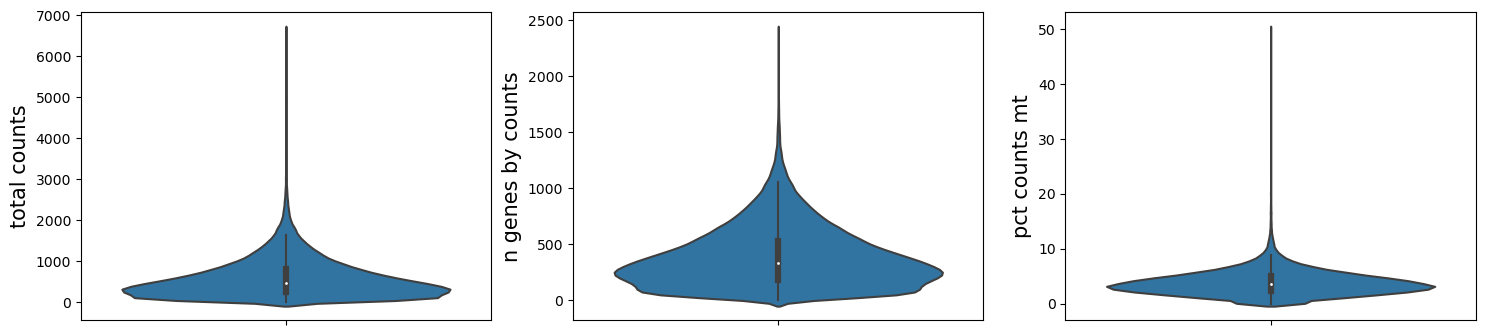

In [8]:
data.plt.violin()

Column
    [0] Markdown(str)
    [1] Row
        [0] TextInput(name='file name', placeholder='Enter a file name...', width=200)
        [1] IntInput(name='dpi', placeholder='Enter the dip...', start=0, value=100, width=200)
    [2] Row
        [0] Button(button_type='primary', name='export', width=100)
        [1] StaticText(width=800)

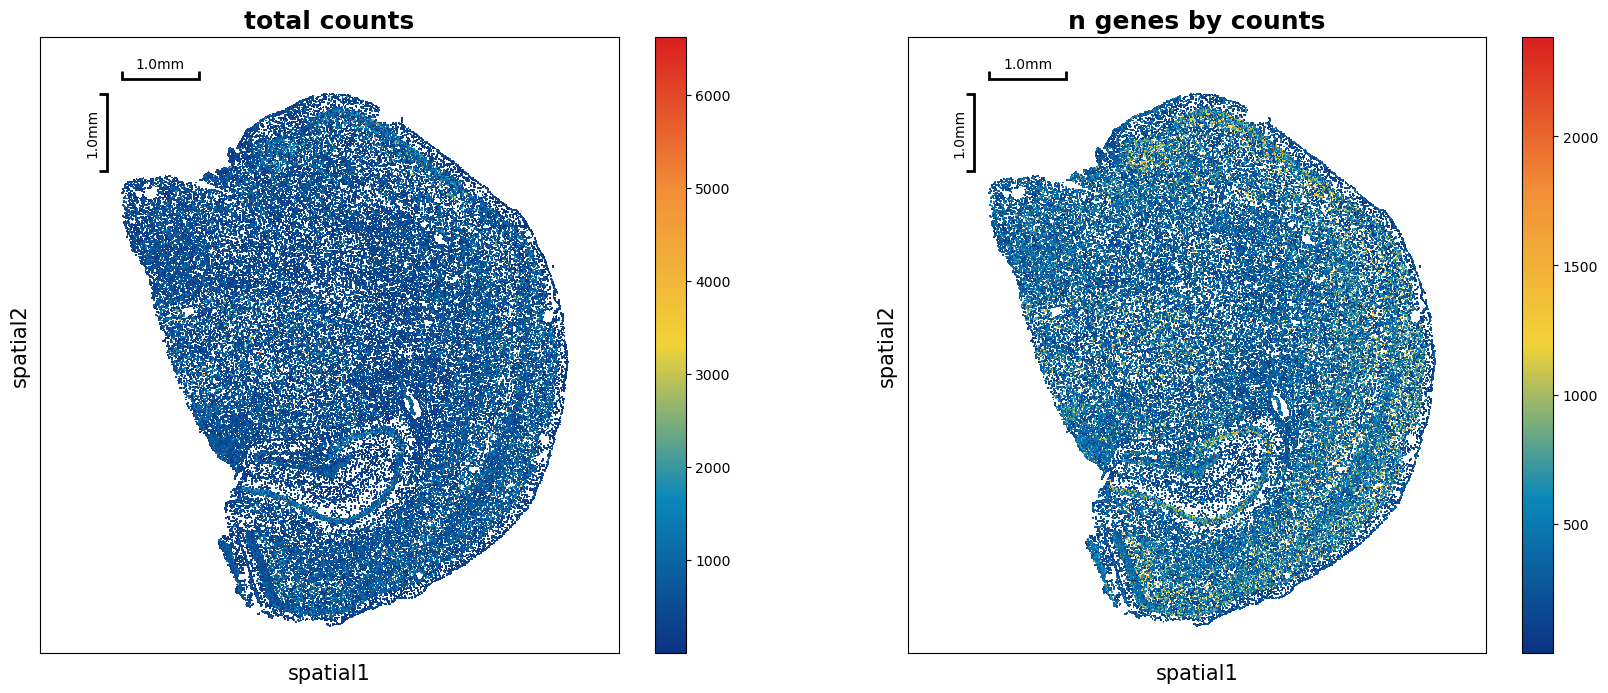

In [9]:
data.plt.spatial_scatter()

In [10]:
data.tl.raw_checkpoint()

In [27]:
adata = st.io.stereo_to_anndata(data,flavor='scanpy',output='/home/chenao/jupyter_home/saw/Demo/outs/scanpy_out.h5ad')

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
[2025-09-25 09:25:27][Stereo][999397][MainThread][139828267292480][reader][711][INFO]: Adding sample in adata.obs['orig.ident'].
[2025-09-25 09:25:27][Stereo][999397][MainThread][139828267292480][reader][714][INFO]: Adding data.position as adata.obsm['spatial'] .
[2025-09-25 09:25:27][Stereo][999397][MainThread][139828267292480][reader][719][INFO]: Adding data.position as adata.obs['x'] and adata.obs['y'] .
[2025-09-25 09:25:27][Stereo][999397][MainThread][139828267292480][reader][822][INFO]: Adding data.tl.raw.exp_matrix as adata.raw .


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
[2025-09-25 09:25:27][Stereo][999397][MainThread][139828267292480][reader][855][INFO]: Finished conversion to anndata.
[2025-09-25 09:25:28][Stereo][999397][MainThread][139828267292480][reader][859][INFO]: Finished output to /home/chenao/jupyter_home/saw/Demo/outs/scanpy_out.h5ad


In [28]:
adata

AnnData object with n_obs × n_vars = 70026 × 27372
    obs: 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'orig.ident', 'x', 'y'
    var: 'n_cells', 'n_counts', 'mean_umi'
    uns: 'bin_type', 'bin_size', 'resolution', 'sn'
    obsm: 'spatial'

这样就成功生成了stereo-seq的sacnpy对象anndata，可以用于下游分析

In [ ]:
# 这样就成功生成了stereo-seq的sacnpy对象anndata，可以用于下游分析
# 当然也可以存为seurat对象在R中分析

#adata = st.io.stereo_to_anndata(data,flavor='seurat',output='seurat_out.h5ad')

# 参考

[10x Genomics官方手册](https://www.10xgenomics.com/)

[SeekSpacetools](https://seekspace.seekgene.com/zh/v1.0.0/index.html)

[SAW用户手册](https://www.stomics.tech/service/saw_8_1/docs/index.html)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 